In [3]:
import pandas as pd
import numpy as np
import seaborn  as sns
import matplotlib.pyplot as plt


In [8]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\mhdfa\Documents\insurance cost prediciton\.venv\Scripts\python.exe
3.15.1 (main, Oct 21 2026, 17:51:31) [MSC v.1951 64 bit (AMD64)]


In [9]:
import sklearn
print(sklearn.__version__)

1.9.1


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder , StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor , GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error



In [12]:
import warnings
warnings.filterwarnings("ignore")


In [13]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = [10,6]
pd.set_option("display.max_columns",None)


In [14]:
data = pd.read_csv("medical_insurance.csv")


In [15]:
data

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
2767,47,female,45.320,1,no,southeast,8569.86180
2768,21,female,34.600,0,no,southwest,2020.17700
2769,19,male,26.030,1,yes,northwest,16450.89470
2770,23,male,18.715,0,no,northwest,21595.38229


In [16]:
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [17]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       2772 non-null   int64  
 1   sex       2772 non-null   str    
 2   bmi       2772 non-null   float64
 3   children  2772 non-null   int64  
 4   smoker    2772 non-null   str    
 5   region    2772 non-null   str    
 6   charges   2772 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 151.7 KB


In [18]:
data.isna().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [20]:
data.describe()

,age,bmi,children,charges
count,2772.000000,2772.000000,2772.000000,2772.000000
mean,39.109668,30.701349,1.101732,13261.369959
std,14.081459,6.129449,1.214806,12151.768945
min,18.000000,15.960000,0.000000,1121.873900
25%,26.000000,26.220000,0.000000,4687.797000
50%,39.000000,30.447500,1.000000,9333.014350
75%,51.000000,34.770000,2.000000,16577.779500
max,64.000000,53.130000,5.000000,63770.428010


In [21]:
data.duplicated().sum()

np.int64(1435)

In [22]:
dup_counts = data.groupby(list(data.columns)).size().reset_index(name = "count")

In [23]:
dup_counts["count"].value_counts().sort_index()

count
2    1288
4      49
Name: count, dtype: int64

In [24]:
data = data.drop_duplicates().reset_index(drop = True)

In [25]:
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Exploratory Data analysis


In [26]:
for col in ["sex","smoker","region"]:
    print("---{col}---")
    print(data[col].value_counts())
    print(data[col].value_counts(normalize = True).round(3))
    

---{col}---
sex
male      675
female    662
Name: count, dtype: int64
sex
male      0.505
female    0.495
Name: proportion, dtype: float64
---{col}---
smoker
no     1063
yes     274
Name: count, dtype: int64
smoker
no     0.795
yes    0.205
Name: proportion, dtype: float64
---{col}---
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64
region
southeast    0.272
southwest    0.243
northwest    0.242
northeast    0.242
Name: proportion, dtype: float64


In [27]:
for col in ["age","bmi","children","charges"]:
    print(f"{col}:skew = {data[col].skew():.3f}, kurtosis = {data[col].kurt():.3f}") 

age:skew = 0.055, kurtosis = -1.244
bmi:skew = 0.284, kurtosis = -0.053
children:skew = 0.937, kurtosis = 0.201
charges:skew = 1.515, kurtosis = 1.604


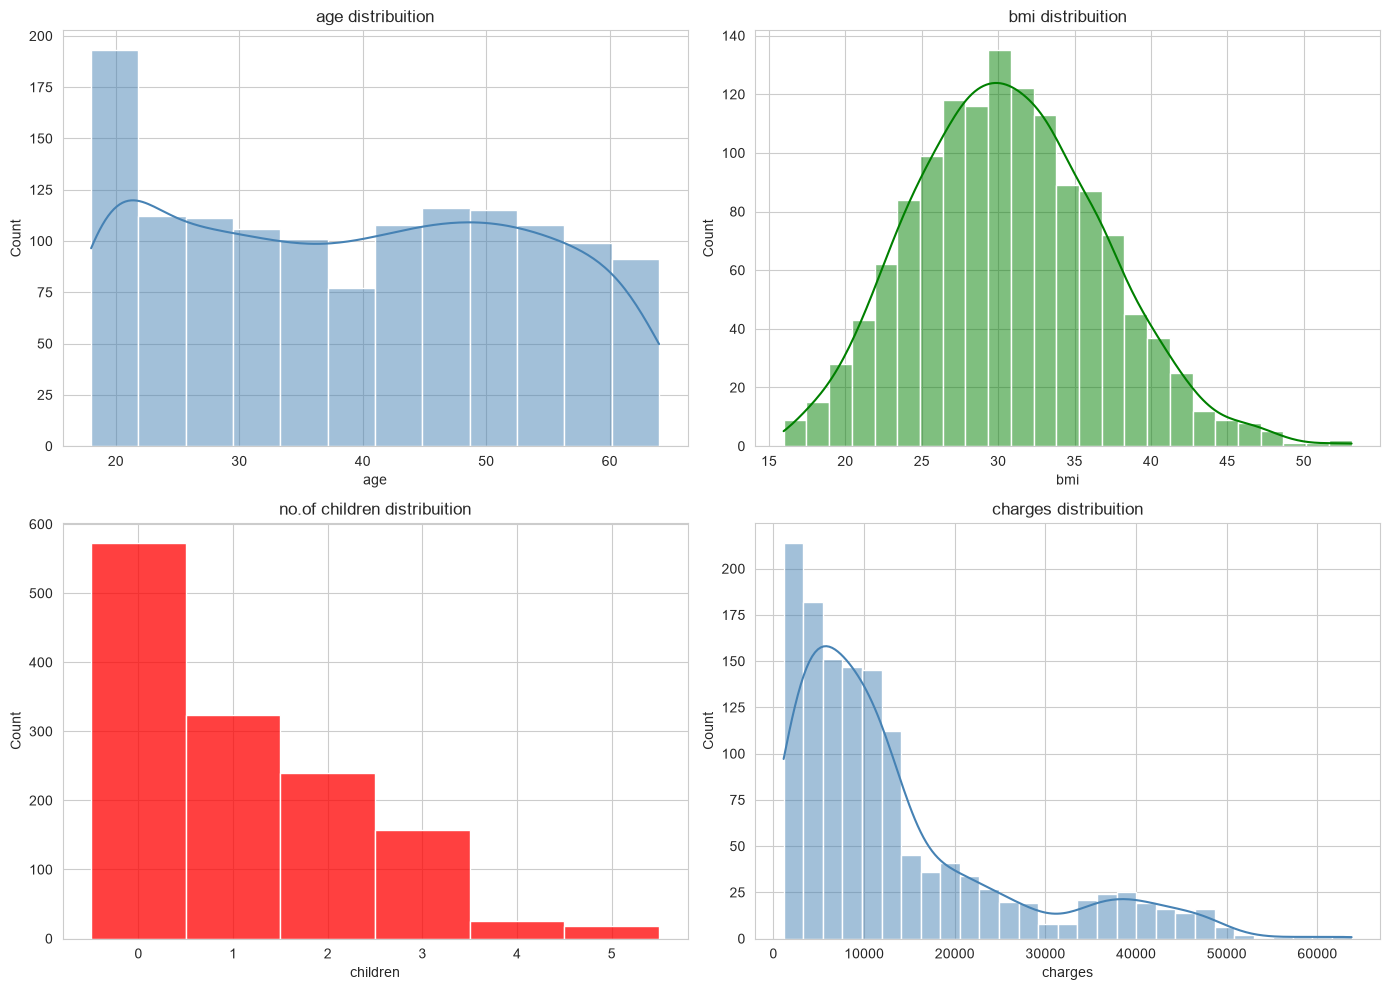

In [28]:
fig , axes = plt.subplots(2,2, figsize = (14,10))

sns.histplot(data["age"],kde = True , ax = axes [0,0] , color ="steelblue")
axes[0,0].set_title("age distribuition")

sns.histplot(data["bmi"],kde = True , ax = axes [0,1] , color ="green")
axes[0,1].set_title("bmi distribuition")

sns.histplot(data["children"],discrete = True , ax = axes [1,0] , color ="red")
axes[1,0].set_title("no.of children distribuition")

sns.histplot(data["charges"],kde = True , ax = axes [1,1] , color ="steelblue")
axes[1,1].set_title("charges distribuition")

plt.tight_layout()
plt.show()


In [29]:
for col in["bmi","charges"]:
    Q1 ,Q3 = data[col].quantile(0.25),data[col].quantile(0.75)

    IQR = Q3-Q1

    lower , upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

    n_out = ((data[col]<lower) | (data[col] > upper)).sum()

    print(f"{col}: bounds = ({lower:.1f} , {upper:.1f},outliers = {n_out} ({n_out/len(data)*100:.1f}%))")
    

bmi: bounds = (13.7 , 47.3,outliers = 9 (0.7%))
charges: bounds = (-13120.7 , 34524.8,outliers = 139 (10.4%))


In [30]:
data.groupby("smoker")["charges"].agg(["mean","median","std","count"])

,mean,median,std,count
smoker,,,,
no,8440.660307,7345.72660,5992.973800,1063
yes,32050.231832,34456.34845,11541.547176,274


In [31]:
def bmi_category(bmi):
    if bmi<18.5:
        return "under weight"
    elif bmi<25:
        return "normal"
    elif bmi<30:
        return "overweight"
    else:
        return "obese"
        

In [32]:
data["bmi_category"]=data["bmi"].apply(bmi_category)

In [33]:
data.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category
0,19,female,27.900,0,yes,southwest,16884.92400,overweight
1,18,male,33.770,1,no,southeast,1725.55230,obese
2,28,male,33.000,3,no,southeast,4449.46200,obese
3,33,male,22.705,0,no,northwest,21984.47061,normal
4,32,male,28.880,0,no,northwest,3866.85520,overweight


In [34]:
data["bmi_category"].value_counts()

bmi_category
obese           706
overweight      386
normal          225
under weight     20
Name: count, dtype: int64

In [35]:
data.groupby("bmi_category")["charges"].mean().sort_values().round(2)

bmi_category
under weight     8852.20
normal          10409.34
overweight      10987.51
obese           15572.04
Name: charges, dtype: float64

In [36]:
data["log_charges"]=np.log1p(data["charges"])


In [37]:
data.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category,log_charges
0,19,female,27.900,0,yes,southwest,16884.92400,overweight,9.734236
1,18,male,33.770,1,no,southeast,1725.55230,obese,7.453882
2,28,male,33.000,3,no,southeast,4449.46200,obese,8.400763
3,33,male,22.705,0,no,northwest,21984.47061,normal,9.998137
4,32,male,28.880,0,no,northwest,3866.85520,overweight,8.260455


In [38]:
data["charges"].skew()

np.float64(1.5153909108403478)

In [39]:
data["log_charges"].skew()

np.float64(-0.08955835073325905)

In [40]:
data_model = pd.get_dummies(
    data,
    columns=["sex","age","smoker","region","bmi_category"],
    drop_first=True  
)
print(data_model.columns.to_list())

['bmi', 'children', 'charges', 'log_charges', 'sex_male', 'age_19', 'age_20', 'age_21', 'age_22', 'age_23', 'age_24', 'age_25', 'age_26', 'age_27', 'age_28', 'age_29', 'age_30', 'age_31', 'age_32', 'age_33', 'age_34', 'age_35', 'age_36', 'age_37', 'age_38', 'age_39', 'age_40', 'age_41', 'age_42', 'age_43', 'age_44', 'age_45', 'age_46', 'age_47', 'age_48', 'age_49', 'age_50', 'age_51', 'age_52', 'age_53', 'age_54', 'age_55', 'age_56', 'age_57', 'age_58', 'age_59', 'age_60', 'age_61', 'age_62', 'age_63', 'age_64', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_category_obese', 'bmi_category_overweight', 'bmi_category_under weight']


In [41]:
feature_cols = [c for c  in data_model.columns if c not in ["charges","log_charges"]]
X = data_model[feature_cols]
y = data_model["log_charges"]


In [42]:
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.2)

In [43]:
y_test_real = np.expm1(y_test)

cantidate_models={
    "LinearRegression" : LinearRegression(),
    "Random Forest" : RandomForestRegressor(n_estimators = 300 , max_depth=6 , n_jobs=-1),
    "Gradient Boosting" :GradientBoostingRegressor(n_estimators = 300 , max_depth=3 ,learning_rate = 0.05)
}
trained_models = {}
metrics_rows = []

for name , model in cantidate_models.items():

        model.fit(X_train,y_train)
        y_pred_log = model.predict(X_test)
        y_pred = np.expm1(y_pred_log)

        r2 = r2_score (y_test_real , y_pred)
        mae = mean_absolute_error(y_test_real, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test_real,y_pred))

        trained_models[name] = model
        metrics_rows.append({"Model":name,"R2":r2, "MAE":mae,"RMSE":rmse})

        print(f"{name} -> R2 : {r2:.4f} - MAE :{mae:.2f}-RMSE:{rmse:.2f}")
        

LinearRegression -> R2 : 0.5023 - MAE :4821.03-RMSE:8895.30
Random Forest -> R2 : 0.7512 - MAE :4190.72-RMSE:6289.69
Gradient Boosting -> R2 : 0.7846 - MAE :3326.99-RMSE:5852.27


In [44]:
results = pd.DataFrame(metrics_rows).sort_values("R2",ascending=False).reset_index(drop=True)


In [45]:
results

,Model,R2,MAE,RMSE
0,Gradient Boosting,0.784579,3326.992690,5852.270865
1,Random Forest,0.751173,4190.724785,6289.693876
2,LinearRegression,0.502310,4821.030158,8895.295024


In [46]:
best_model_name =  results.loc[0,"Model"]
best_model =trained_models[best_model_name]
best_model_name

'Gradient Boosting'

In [47]:
best_model

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.05
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",300
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"init i

In [49]:
import joblib

joblib.dump(best_model,"insurance_model.pkl")
joblib.dump(feature_cols,"model_features.pkl")
joblib.dump(best_model_name,"model_name.pkl")

['model_name.pkl']